## **Case-Based Reasoning ( CBR )**

CBR has **no explicit rules**: it solves a new problem by **retrieving the most similar past cases**, reusing their solutions, revising the answer and retaining the useful new cases. This notebook keeps the original implementation and adds **explanation by precedent, the choice of *k* and of the attribute weights by cross-validation ( without leakage ), a correctness check of the retrieval, bootstrap intervals and reference models**.

**Notebooks of this series:** 1. CN2 Rule Induction · 2. Expert Systems · 3. Case-Based Reasoning · 4. Apriori for Classification ( CBA ) · 5. Simple Rule Learners ( ZeroR, OneR, PRISM ) · 6. RIPPER · 7. Rules from Decision Trees · 8. RuleFit · 9. Fuzzy Rule-Based Classifier

### **0. Environment Setup**

In [1]:
#Import Libs
import sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

In [2]:
#Define Colors Palette and Standards for Illustrations
RED, DARK, GRAY, LIGHT, SOFT = "#CD2027", "#404040", "#7F7F7F", "#D9D9D9", "#E9A0A3"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.prop_cycle": cycler(color=[RED, DARK, SOFT, GRAY]),
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

In [3]:
#Helper Functions: Evaluation Reports ( Confusion Matrix, Metrics, ROC and Precision-Recall )
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, log_loss, matthews_corrcoef,
                             confusion_matrix, roc_curve, precision_recall_curve)

def plot_confusion(cm, labels, ax, title="Confusion matrix"):
    ax.imshow(cm, cmap="Reds"); ax.grid(False)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45 if len(labels) > 4 else 0, ha="right" if len(labels) > 4 else "center")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10 if len(labels) > 4 else 13,
                    color="white" if cm[i, j] > cm.max() / 2 else DARK)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)

def report_binary(y_true, y_pred, y_score, name="model", labels=("negative", "positive"), plot=True):
    """Confusion matrix, ROC and Precision-Recall curves + a Series with the main metrics (positive class = 1)."""
    y_true, y_pred, y_score = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_score)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "precision": precision_score(y_true, y_pred, zero_division=0), "recall": recall_score(y_true, y_pred),
               "F1": f1_score(y_true, y_pred), "MCC": matthews_corrcoef(y_true, y_pred),
               "ROC AUC": roc_auc_score(y_true, y_score), "PR AUC": average_precision_score(y_true, y_score)}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
        plot_confusion(confusion_matrix(y_true, y_pred), list(labels), axes[0], f"Confusion matrix – {name}")
        fpr, tpr, _ = roc_curve(y_true, y_score)
        axes[1].plot(fpr, tpr, color=RED, lw=2.4, label=f"AUC = {metrics['ROC AUC']:.3f}"); axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--")
        axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")
        p, r, _ = precision_recall_curve(y_true, y_score)
        axes[2].plot(r, p, color=DARK, lw=2.4, label=f"AP = {metrics['PR AUC']:.3f}"); axes[2].axhline(y_true.mean(), color=GRAY, ls="--")
        axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision"); axes[2].set_title("Precision–Recall curve"); axes[2].legend(loc="lower left")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)

def report_multiclass(y_true, y_pred, y_proba, labels, name="model", plot=True):
    """Confusion matrix, one-vs-rest ROC curves and per-class F1 + a Series with the main metrics."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    k = len(labels)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "macro precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
               "macro recall": recall_score(y_true, y_pred, average="macro"), "macro F1": f1_score(y_true, y_pred, average="macro"),
               "MCC": matthews_corrcoef(y_true, y_pred), "ROC AUC (ovr)": roc_auc_score(y_true, y_proba, multi_class="ovr"),
               "log loss": log_loss(y_true, y_proba, labels=list(range(k)))}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.1, 1, 1]})
        plot_confusion(confusion_matrix(y_true, y_pred, labels=list(range(k))), list(labels), axes[0], f"Confusion matrix – {name}")
        cmap = plt.get_cmap("tab10")
        for c in range(k):
            fpr, tpr, _ = roc_curve((y_true == c).astype(int), y_proba[:, c])
            axes[1].plot(fpr, tpr, color=cmap(c), lw=1.6, label=f"{labels[c]}")
        axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
        axes[1].set_title(f"ROC one-vs-rest (macro AUC = {metrics['ROC AUC (ovr)']:.3f})"); axes[1].legend(fontsize=7, ncol=2 if k > 5 else 1, loc="lower right")
        f1s = f1_score(y_true, y_pred, average=None)
        axes[2].bar(range(k), f1s, color=RED, width=0.65); axes[2].set_xticks(range(k)); axes[2].set_xticklabels(labels, rotation=45 if k > 4 else 0, ha="right" if k > 4 else "center")
        axes[2].set_ylim(0, 1.05); axes[2].set_ylabel("F1"); axes[2].set_title("F1 per class")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)
def annotate_heatmap(ax, mat, fmt="{:.2f}"):
    """Write the values on an imshow heat map with a readable text color."""
    mat = np.asarray(mat, dtype=float)
    lo, hi = np.nanmin(mat), np.nanmax(mat)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat[i, j]
            ax.text(j, i, "–" if np.isnan(v) else fmt.format(v), ha="center", va="center", color="white" if (not np.isnan(v) and v > (lo + hi) / 2) else DARK)

### **1. Rule-Based Techniques**

Models whose knowledge is a set of **IF ⟶ THEN** rules: transparent, auditable and easy to explain.

| Technique | Where the rules come from | Idea |
|---|---|---|
| **CN2** | learned from data | ordered rule list built by beam search (entropy + significance test) |
| **Expert system** | written by specialists | inference engine + knowledge base, with certainty factors |
| **Case-Based Reasoning** | no explicit rules: past **cases** | retrieve · reuse · revise · retain |
| **Apriori (CBA)** | mined from data | class association rules: frequent itemsets → class |

This notebook focuses on **Case-Based Reasoning**. All the techniques of the series are applied to the same problem: **malignant × benign** tumours ( Breast Cancer dataset ).

### **2. Dataset and Preparation**

* Positive class = **malignant** (1) · 10 *mean* attributes (readable rules)
* Train/test split **70/30**, stratified
* For CN2 and Apriori the attributes are **discretised** in 3 quantile bins (*low / mid / high*), fitted on the **training set only**

In [4]:
#Load the Breast Cancer Dataset ( Positive Class = Malignant )
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer(as_frame=True)
cols = [c for c in data.data.columns if c.startswith("mean ")]            # 10 "mean" attributes
X = data.data[cols]
y = (data.target == 0).astype(int)                                        # 1 = malignant, 0 = benign
CLASS_NAMES = ["benign", "malignant"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
print("train:", X_train.shape, "| test:", X_test.shape, "| malignant in train:", f"{y_train.mean():.1%}")
X_train.head(3)

train: (398, 10) | test: (171, 10) | malignant in train: 37.2%


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension
78,20.18,23.97,143.70,1245.0,0.129,0.345,0.375,0.160,0.291,0.081
330,16.03,15.51,105.80,793.2,0.095,0.137,0.120,0.070,0.178,0.060
378,13.66,15.15,88.27,580.6,0.083,0.075,0.042,0.025,0.179,0.059


### **3. Case-Based Reasoning (CBR)**

There are **no explicit rules**: the knowledge is a **case base**. For a new problem the **CBR cycle** is:

1. **Retrieve:** the most **similar** past cases
2. **Reuse:** adapt their solutions (here, a similarity-weighted vote)
3. **Revise:** check the confidence – low confidence goes to a human
4. **Retain:** store the new, confirmed case when it is useful

In [15]:
#CBR Implementation ( Retrieve, Reuse, Revise, Retain )
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif

class CaseBasedReasoner:
    def __init__(self, k=5, weights=None):
        self.k, self.weights = k, weights

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.scaler_ = StandardScaler().fit(X)
        self.cases_, self.labels_ = self.scaler_.transform(X), np.asarray(y)
        self.w_ = np.ones(X.shape[1]) if self.weights is None else np.asarray(self.weights)
        return self

    def retrieve(self, Xq):                                              # RETRIEVE: weighted distance -> similarity
        Q = self.scaler_.transform(np.asarray(Xq, dtype=float))
        d = np.sqrt((((Q[:, None, :] - self.cases_[None, :, :]) ** 2) * self.w_).sum(axis=2))
        idx = np.argsort(d, axis=1)[:, :self.k]
        return idx, 1 / (1 + np.take_along_axis(d, idx, axis=1))

    def predict_proba(self, Xq):                                         # REUSE: similarity-weighted vote
        idx, sim = self.retrieve(Xq)
        votes = (self.labels_[idx] * sim).sum(axis=1) / sim.sum(axis=1)
        return np.c_[1 - votes, votes]

    def predict(self, Xq):
        return (self.predict_proba(Xq)[:, 1] > 0.5).astype(int)

    def retain(self, x, label):                                          # RETAIN: store the confirmed case
        self.cases_ = np.vstack([self.cases_, self.scaler_.transform(x.reshape(1, -1))]); self.labels_ = np.append(self.labels_, label)

cbr = CaseBasedReasoner(k=5).fit(X_train, y_train)
proba_cbr = cbr.predict_proba(X_test)[:, 1]
print("case base:", cbr.cases_.shape[0], "cases ×", cbr.cases_.shape[1], "attributes")

case base: 398 cases × 10 attributes


In [ ]:
#Dictionary Used to Collect the Test Metrics of This Notebook ( the Cells Below Add Their Results to It )
results = {}

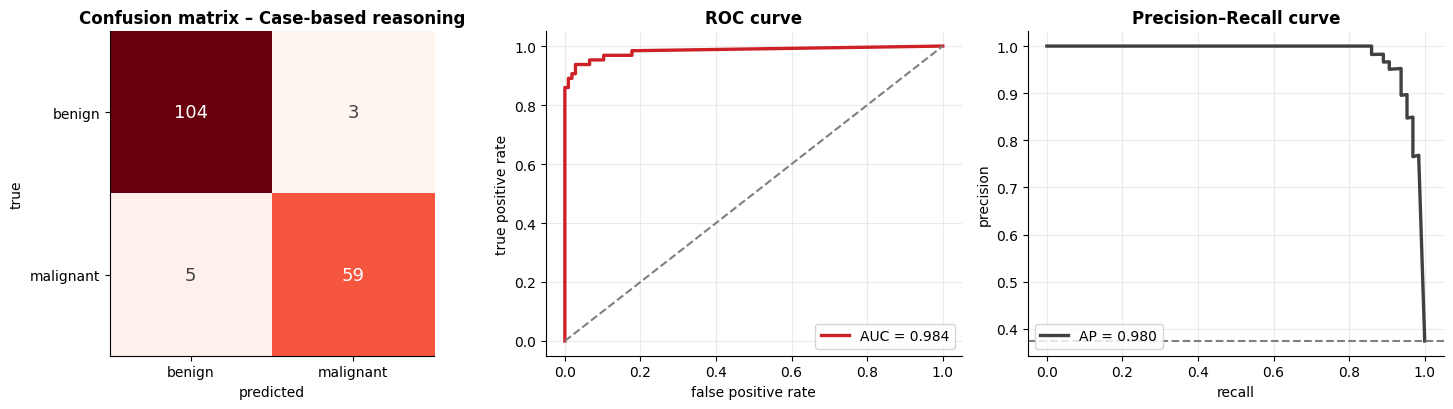

,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
Case-based reasoning,0.953,0.947,0.952,0.922,0.937,0.9,0.984,0.98


In [16]:
#Evaluate CBR on the Test Set
results["CBR"] = report_binary(y_test, cbr.predict(X_test), proba_cbr, "Case-based reasoning", CLASS_NAMES)
results["CBR"].to_frame().T

#### **CBR-Specific Metrics**

* **Retrieval quality:** similarity of the retrieved cases and **precision@k** (share of retrieved cases with the same class as the query)
* **Revise step:** accuracy × **coverage** when low-confidence answers are sent to a human
* **Retain step:** accuracy × **case-base size** under different retention policies

mean similarity of retrieved cases: 0.476 | precision@5: 0.924


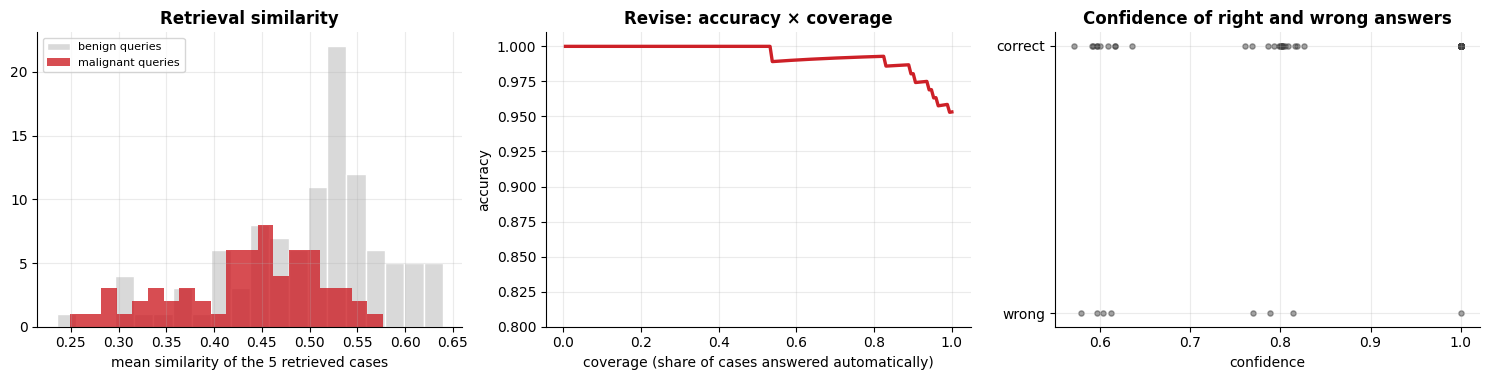

In [17]:
#Retrieval Quality and the Revise Step ( Accuracy x Coverage )
idx, sim = cbr.retrieve(X_test)
precision_at_k = (cbr.labels_[idx] == y_test.to_numpy()[:, None]).mean(axis=1)
print(f"mean similarity of retrieved cases: {sim.mean():.3f} | precision@5: {precision_at_k.mean():.3f}")

conf = np.maximum(proba_cbr, 1 - proba_cbr)                                  # confidence of the answer
order = np.argsort(-conf)
correct = (cbr.predict(X_test) == y_test.to_numpy())[order]
coverage = np.arange(1, len(order) + 1) / len(order)
acc_at_cov = np.cumsum(correct) / np.arange(1, len(order) + 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
axes[0].hist(sim.mean(axis=1)[y_test == 0], bins=20, color=LIGHT, edgecolor="white", label="benign queries")
axes[0].hist(sim.mean(axis=1)[y_test == 1], bins=20, color=RED, alpha=0.8, label="malignant queries"); axes[0].set_xlabel("mean similarity of the 5 retrieved cases"); axes[0].set_title("Retrieval similarity"); axes[0].legend(fontsize=8)
axes[1].plot(coverage, acc_at_cov, color=RED, lw=2.4); axes[1].set_xlabel("coverage (share of cases answered automatically)"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Revise: accuracy × coverage"); axes[1].set_ylim(0.8, 1.01)
axes[2].scatter(conf, correct[np.argsort(order)], s=14, color=DARK, alpha=0.5); axes[2].set_xlabel("confidence"); axes[2].set_yticks([0, 1]); axes[2].set_yticklabels(["wrong", "correct"]); axes[2].set_title("Confidence of right and wrong answers")
plt.tight_layout(); plt.show()

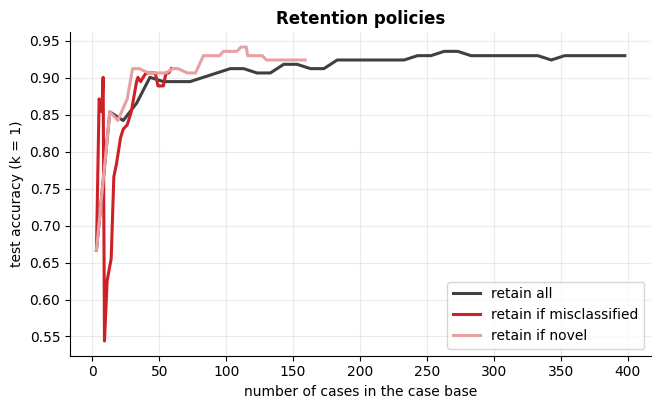

,policy,final case-base size,final test accuracy
0,retain all,398,0.930
1,retain if misclassified,59,0.912
2,retain if novel,159,0.924


In [18]:
#Retain Step: Accuracy x Case-Base Size for Three Retention Policies
rng = np.random.default_rng(RANDOM_STATE)
Xtr_np, ytr_np = X_train.to_numpy(), y_train.to_numpy()
stream = rng.permutation(len(Xtr_np))
seed_ids = [stream[np.where(ytr_np[stream] == c)[0][0]] for c in (0, 1)]                        # start with one case of each class
stream = [i for i in stream if i not in seed_ids]

def run_policy(policy, novelty=1.6):
    model = CaseBasedReasoner(k=1).fit(X_train.iloc[seed_ids], y_train.iloc[seed_ids])
    sizes, accs = [], []
    for step, i in enumerate(stream):
        x, label = Xtr_np[i], ytr_np[i]
        if policy == "retain all":
            keep = True
        else:
            idx, sim = model.retrieve(x.reshape(1, -1)); nearest = model.labels_[idx[0, 0]]
            dist = 1 / sim[0, 0] - 1
            keep = (nearest != label) if policy == "retain if misclassified" else (dist > novelty)
        if keep:
            model.retain(x, label)
        if step % 10 == 0 or step == len(stream) - 1:
            sizes.append(len(model.labels_)); accs.append((model.predict(X_test) == y_test.to_numpy()).mean())
    return np.array(sizes), np.array(accs)

plt.figure()
summary_rows = []
for policy, color in zip(["retain all", "retain if misclassified", "retain if novel"], [DARK, RED, SOFT]):
    s_, a_ = run_policy(policy)
    plt.plot(s_, a_, color=color, lw=2.2, label=policy); summary_rows.append((policy, int(s_[-1]), a_[-1]))
plt.xlabel("number of cases in the case base"); plt.ylabel("test accuracy (k = 1)"); plt.legend(); plt.title("Retention policies")
plt.show()
pd.DataFrame(summary_rows, columns=["policy", "final case-base size", "final test accuracy"])

Retaining **only useful cases** (misclassified or novel) gives a **much smaller** case base for a **small drop** in accuracy – the key to scaling CBR.

In [19]:
#Attribute Weighting ( Mutual Information ) in the Similarity Measure
w = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)
w = w / w.max()
cbr_w = CaseBasedReasoner(k=5, weights=w).fit(X_train, y_train)
print(pd.Series(w, index=X_train.columns).round(2).sort_values(ascending=False).head(4).to_dict())
rows = [("unweighted", roc_auc_score(y_test, proba_cbr), accuracy_score(y_test, cbr.predict(X_test))),
        ("weighted by mutual information", roc_auc_score(y_test, cbr_w.predict_proba(X_test)[:, 1]), accuracy_score(y_test, cbr_w.predict(X_test)))]
pd.DataFrame(rows, columns=["similarity", "ROC AUC", "accuracy"])

{'mean concave points': 1.0, 'mean perimeter': 0.91, 'mean radius': 0.86, 'mean area': 0.84}


,similarity,ROC AUC,accuracy
0,unweighted,0.984,0.953
1,weighted by mutual information,0.990,0.953


### **4. Quality Metrics Beyond the Original Ones**

In [ ]:
#Correctness of the Retrieval: Same Neighbours as scikit-learn's NearestNeighbors ( Unweighted Distance )
from sklearn.neighbors import NearestNeighbors
idx_ours, _ = cbr.retrieve(X_test)
nn = NearestNeighbors(n_neighbors=5).fit(cbr.cases_)
idx_ref = nn.kneighbors(cbr.scaler_.transform(X_test.to_numpy()), return_distance=False)
same_sets = np.mean([set(a) == set(b_) for a, b_ in zip(idx_ours, idx_ref)])
print(f"test cases with exactly the same 5 retrieved cases as the library: {same_sets:.1%}")

In [ ]:
#Explanation by Precedent: the Retrieved Cases of One Correct and One Wrong Answer
pred_cbr = cbr.predict(X_test)
idx_q, sim_q = cbr.retrieve(X_test)
wrong = np.flatnonzero(pred_cbr != y_test.to_numpy())
right = np.flatnonzero(pred_cbr == y_test.to_numpy())
show_cols = ["mean radius", "mean concave points", "mean area"]
for name, pos in [("correct answer", right[0]), ("wrong answer", wrong[0] if len(wrong) else right[1])]:
    print(f"--- {name}: true class = {CLASS_NAMES[y_test.iloc[pos]]}, answer = {CLASS_NAMES[pred_cbr[pos]]}, P(malignant) = {proba_cbr[pos]:.2f}")
    query = X_test.iloc[pos][show_cols].round(3).to_dict()
    print("   query:", query)
    for rank, (case_id, s) in enumerate(zip(idx_q[pos], sim_q[pos]), 1):
        original = X_train.iloc[case_id][show_cols].round(3).to_dict()
        print(f"   {rank}. similarity {s:.2f} | class = {CLASS_NAMES[cbr.labels_[case_id]]:<9} | {original}")

In [ ]:
#Choice of k and of the Attribute Weights by Repeated CV ( the Weights Are Computed Inside Every Training Fold )
from sklearn.model_selection import RepeatedStratifiedKFold
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

def cv_cbr(k, weighted):
    accs, aucs = [], []
    for tr, te in cv_rep.split(X_train, y_train):
        Xa, ya, Xb, yb = X_train.iloc[tr], y_train.iloc[tr], X_train.iloc[te], y_train.iloc[te]
        wts = None
        if weighted:
            wts = mutual_info_classif(Xa, ya, random_state=RANDOM_STATE)
            wts = wts / wts.max()
        model = CaseBasedReasoner(k=k, weights=wts).fit(Xa, ya)
        p = model.predict_proba(Xb)[:, 1]
        accs.append(((p > 0.5).astype(int) == yb.to_numpy()).mean()); aucs.append(roc_auc_score(yb, p))
    return np.mean(accs), np.mean(aucs)

grid = [(k, w) for w in (False, True) for k in (1, 3, 5, 9, 15, 25)]
cv_cbr_table = pd.DataFrame([{"k": k, "similarity": "weighted by mutual information" if w else "unweighted", "CV accuracy": cv_cbr(k, w)[0], "CV ROC AUC": cv_cbr(k, w)[1]} for k, w in grid])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col in zip(axes, ["CV accuracy", "CV ROC AUC"]):
    for (label, g), color in zip(cv_cbr_table.groupby("similarity"), [DARK, RED]):
        ax.plot(g["k"], g[col], marker="o", color=color, label=label)
    ax.set_xlabel("k ( retrieved cases )"); ax.set_title(col); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
cv_cbr_table.round(3)

In [ ]:
#Uncertainty of the Test Metrics ( Bootstrap of the Test Cases, 1,000 Resamples )
def bootstrap_ci(y_true, pred, score, n_boot=1000, seed=RANDOM_STATE):
    rng_b = np.random.default_rng(seed)
    y_true, pred, score = np.asarray(y_true), np.asarray(pred), np.asarray(score)
    acc, auc = [], []
    for _ in range(n_boot):
        i = rng_b.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[i])) < 2:
            continue
        acc.append((pred[i] == y_true[i]).mean())
        auc.append(roc_auc_score(y_true[i], score[i]))
    return pd.DataFrame({"accuracy": np.percentile(acc, [2.5, 50, 97.5]), "ROC AUC": np.percentile(auc, [2.5, 50, 97.5])}, index=["2.5%", "median", "97.5%"]).T

print("the test set has", len(y_test), "cases: differences smaller than these intervals are not reliable")
bootstrap_ci(y_test, pred_cbr, proba_cbr).round(3)

In [ ]:
#Calibration of the Predicted Probabilities ( Brier Score and Reliability Curve )
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

proba_cbr_ARRAY = np.asarray(proba_cbr, dtype=float)
frac_pos, mean_pred = calibration_curve(y_test, proba_cbr_ARRAY, n_bins=5, strategy="quantile")                       # bins with the same number of cases
print(f"Brier score: {brier_score_loss(y_test, proba_cbr_ARRAY):.4f} | Brier score of a model that always predicts the training prevalence: {brier_score_loss(y_test, np.full(len(y_test), y_train.mean())):.4f} ( lower is better )")
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", label="perfect calibration"); ax.plot(mean_pred, frac_pos, color=RED, marker="o", label="CBR")
ax.set_xlabel("mean predicted probability ( 5 bins of equal size )"); ax.set_ylabel("observed share of malignant"); ax.set_title("Reliability curve"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
#Reference Models on the Same Split ( Is the Technique Better than a Trivial or a Standard Model? )
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

references = {"Majority class": DummyClassifier(strategy="prior"),
              "Decision tree ( depth 3 )": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
              "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))}
reference_rows = {}
for ref_name, model in references.items():
    model.fit(X_train, y_train)
    reference_rows[ref_name] = report_binary(y_test, model.predict(X_test), model.predict_proba(X_test)[:, 1], ref_name, CLASS_NAMES, plot=False)
metric_cols = ["accuracy", "precision", "recall", "F1", "ROC AUC", "PR AUC"]
pd.concat([pd.DataFrame(results).T[metric_cols], pd.DataFrame(reference_rows).T[metric_cols]]).round(3)

### **5. Takeaways**

* **Explanation by precedent:** the answer is justified by the retrieved cases; a wrong answer is usually a case whose neighbours are from the other class, which a person can inspect
* The retrieval was **checked against a reference implementation**; it is the same nearest-neighbour search with a similarity-weighted vote
* *k* and the weights were compared with **cross-validation on the training set only**, with the weights recomputed inside each fold: weights computed on all the training cases would leak the labels of the validation cases. In this data the mutual-information weights did **not** improve the cross-validated accuracy over the unweighted distance, so the small gain of the single test split ( original cell ) should not be trusted
* CBR is memory-based: its cost grows with the case base ( the *retain* policies of section 3 control it ) and its probabilities are only as good as the neighbourhood